In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, MinMaxScaler


In [2]:
df = pd.read_csv("india_housing_prices.csv")

In [3]:
print("the shape of the dataset", df.shape)
print("Missing values", df.isna().sum())


print("basic info of the dataset()", df.info())

print(df.head())


print(df.columns)

the shape of the dataset (250000, 23)
Missing values ID                                0
State                             0
City                              0
Locality                          0
Property_Type                     0
BHK                               0
Size_in_SqFt                      0
Price_in_Lakhs                    0
Price_per_SqFt                    0
Year_Built                        0
Furnished_Status                  0
Floor_No                          0
Total_Floors                      0
Age_of_Property                   0
Nearby_Schools                    0
Nearby_Hospitals                  0
Public_Transport_Accessibility    0
Parking_Space                     0
Security                          0
Amenities                         0
Facing                            0
Owner_Type                        0
Availability_Status               0
dtype: int64
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250000 entries, 0 to 249999
Data columns (total 23 colum

In [4]:
### Step 2: Handle missing values and duplicates

df = df.drop_duplicates().copy()

df = df.replace("^\s*$",np.nan,regex = True)
df= df.drop(columns = 'ID')


In [5]:
print("missing values before fill")
print(df.isna().sum().sort_values(ascending = False).head())

missing values before fill
State         0
City          0
Owner_Type    0
Facing        0
Amenities     0
dtype: int64


In [6]:
num_column = [ "BHK", "Size_in_SqFt", "Price_in_Lakhs", "Price_per_SqFt", "Year_Built",
    "Floor_No", "Total_Floors", "Age_of_Property", "Nearby_Schools",
    "Nearby_Hospitals","Parking_Space","Security"]

df[num_column].dtypes


print(df["Parking_Space"].unique())
print(df["Security"].unique())


for col in ["Parking_Space","Security"]:
    if col in df.columns:
        df[col] = df[col].map({"Yes": 1, "No" : 0})

for col in num_column:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col],errors = "coerce")

cat_col = [
    "State", "City", "Locality", "Property_Type", "Furnished_Status",
    "Facing", "Owner_Type", "Availability_Status", "Amenities", "Public_Transport_Accessibility"
]

for col in cat_col:
    if col in df.columns:
        df[col] = df[col].fillna("Unknown" if col!="Amenities" else "None")


print("missing values after fill")
print(df.isna().sum().sort_values(ascending = False).head())


        

['No' 'Yes']
['No' 'Yes']
missing values after fill
State         0
City          0
Owner_Type    0
Facing        0
Amenities     0
dtype: int64


In [7]:
def build_future_price(df, city_growth_rates):
    df = df.copy()
    cities = df['City']
 

    growth_rates = cities.map(
        lambda c: city_growth_rates.get(c, city_growth_rates['default'])
    )

    df['Future_Price_5Y'] = (df['Price_in_Lakhs'] * (1 + growth_rates) ** 5).round(2)

    print("Sample — Current vs Projected Price:")
    print(df[['Price_in_Lakhs', 'Future_Price_5Y']].head(10).to_string(index=False))

    return df


city_growth_rates = {
    'Mumbai': 0.10, 'Delhi': 0.10, 'Bangalore': 0.10, 'Hyderabad': 0.10,
    'Chennai': 0.09, 'Pune': 0.09, 'Kolkata': 0.09,
    'Ahmedabad': 0.08, 'Jaipur': 0.08, 'Lucknow': 0.08,
    'Surat': 0.08, 'Bhopal': 0.08, 'Indore': 0.08,
    'default': 0.07
}

df = build_future_price(df, city_growth_rates)


Sample — Current vs Projected Price:
 Price_in_Lakhs  Future_Price_5Y
         489.76           753.56
         195.52           300.83
         183.79           257.77
         300.29           421.17
         182.90           268.74
         135.28           189.74
         318.12           446.18
         141.39           198.31
         189.16           265.31
         187.42           262.87


In [8]:
def build_good_investment_label(df):
    df = df.copy()

    city_median_price = df.groupby('City')['Price_in_Lakhs'].transform('median')
    dataset_median_ppsf = df['Price_per_SqFt'].median()

    # Explicitly ensure these columns are numeric before comparison
    # Coerce errors to NaN, then fill with a sensible value like 0 or median
    df['Nearby_Schools'] = pd.to_numeric(df['Nearby_Schools'], errors='coerce').fillna(0).astype(int)
    df['Public_Transport_Accessibility'] = pd.to_numeric(df['Public_Transport_Accessibility'], errors='coerce').fillna(0).astype(int)


    c1 = df['Price_in_Lakhs'] <= city_median_price
    c2 = df['Price_per_SqFt'] <= dataset_median_ppsf
    c3 = df['Nearby_Schools'] >= 2
    c4 = df['Public_Transport_Accessibility'] >= 2

    conditions = c1.astype(int) + c2.astype(int) + c3.astype(int) + c4.astype(int)
    df['Good_Investment'] = (conditions >= 2).astype(int)

    print("Good_Investment Value Counts:")
    print(df['Good_Investment'].value_counts())
    print(f"\nClass Balance: {df['Good_Investment'].mean():.2%} positive class")

    return df

df = build_good_investment_label(df)

Good_Investment Value Counts:
Good_Investment
1    148360
0    101640
Name: count, dtype: int64

Class Balance: 59.34% positive class


In [9]:
df.to_csv("ML_file.csv")

In [10]:
#Normalise the num feature

scale_columns = [
    "BHK", "Size_in_SqFt", "Price_in_Lakhs", "Price_per_SqFt",
    "Year_Built", "Floor_No", "Total_Floors", "Age_of_Property",
    "Nearby_Schools", "Nearby_Hospitals"
]

scaler = MinMaxScaler()
df[scale_columns] = scaler.fit_transform(df[scale_columns])

df[scale_columns].head()

,BHK,Size_in_SqFt,Price_in_Lakhs,Price_per_SqFt,Year_Built,Floor_No,Total_Floors,Age_of_Property,Nearby_Schools,Nearby_Hospitals
0,0.00,0.942222,0.979102,0.101010,0.000000,0.733333,0.000000,1.000000,1.000000,0.222222
1,0.50,0.414222,0.378612,0.080808,0.545455,0.700000,0.655172,0.454545,0.777778,0.000000
2,0.25,0.698222,0.354673,0.050505,0.212121,0.633333,0.896552,0.787879,0.888889,0.777778
3,0.25,0.498000,0.592429,0.111111,0.030303,0.700000,0.862069,0.969697,0.444444,0.666667
4,0.75,0.960667,0.352857,0.040404,0.363636,0.100000,0.034483,0.636364,0.333333,0.888889


In [11]:
categorical_columns = [
    "Location", "Property_Type", "Furnished_Status", "Facing", "Owner_Type", "Availability_Status"
]

for col in categorical_columns:
    if col in df.columns:
        encoder = LabelEncoder()
        df[col] = encoder.fit_transform(df[col].astype(str))

print("Columns after encoding:", len(df.columns))
print(df.columns[:10].tolist())

Columns after encoding: 24
['State', 'City', 'Locality', 'Property_Type', 'BHK', 'Size_in_SqFt', 'Price_in_Lakhs', 'Price_per_SqFt', 'Year_Built', 'Furnished_Status']


In [12]:
df.to_csv("Cleaned_dataset.csv")

In [13]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor,HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import roc_auc_score, confusion_matrix, classification_report
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler,OrdinalEncoder
from sklearn.base import clone

from xgboost import XGBClassifier, XGBRegressor

In [14]:
df= pd.read_csv("ML_file.csv")

df.head()

,Unnamed: 0,State,City,Locality,Property_Type,BHK,Size_in_SqFt,Price_in_Lakhs,Price_per_SqFt,Year_Built,...,Nearby_Hospitals,Public_Transport_Accessibility,Parking_Space,Security,Amenities,Facing,Owner_Type,Availability_Status,Future_Price_5Y,Good_Investment
0,0,Tamil Nadu,Chennai,Locality_84,Apartment,1,4740,489.76,0.10,1990,...,3,0,0,0,"Playground, Gym, Garden, Pool, Clubhouse",West,Owner,Ready_to_Move,753.56,0
1,1,Maharashtra,Pune,Locality_490,Independent House,3,2364,195.52,0.08,2008,...,1,0,0,1,"Playground, Clubhouse, Pool, Gym, Garden",North,Builder,Under_Construction,300.83,1
2,2,Punjab,Ludhiana,Locality_167,Apartment,2,3642,183.79,0.05,1997,...,8,0,1,0,"Clubhouse, Pool, Playground, Gym",South,Broker,Ready_to_Move,257.77,1
3,3,Rajasthan,Jodhpur,Locality_393,Independent House,2,2741,300.29,0.11,1991,...,7,0,1,1,"Playground, Clubhouse, Gym, Pool, Garden",North,Builder,Ready_to_Move,421.17,0
4,4,Rajasthan,Jaipur,Locality_466,Villa,4,4823,182.90,0.04,2002,...,9,0,0,1,"Playground, Garden, Gym, Pool, Clubhouse",East,Builder,Ready_to_Move,268.74,1


In [15]:
df.drop(columns="Unnamed: 0")

,State,City,Locality,Property_Type,BHK,Size_in_SqFt,Price_in_Lakhs,Price_per_SqFt,Year_Built,Furnished_Status,...,Nearby_Hospitals,Public_Transport_Accessibility,Parking_Space,Security,Amenities,Facing,Owner_Type,Availability_Status,Future_Price_5Y,Good_Investment
0,Tamil Nadu,Chennai,Locality_84,Apartment,1,4740,489.76,0.10,1990,Furnished,...,3,0,0,0,"Playground, Gym, Garden, Pool, Clubhouse",West,Owner,Ready_to_Move,753.56,0
1,Maharashtra,Pune,Locality_490,Independent House,3,2364,195.52,0.08,2008,Unfurnished,...,1,0,0,1,"Playground, Clubhouse, Pool, Gym, Garden",North,Builder,Under_Construction,300.83,1
2,Punjab,Ludhiana,Locality_167,Apartment,2,3642,183.79,0.05,1997,Semi-furnished,...,8,0,1,0,"Clubhouse, Pool, Playground, Gym",South,Broker,Ready_to_Move,257.77,1
3,Rajasthan,Jodhpur,Locality_393,Independent House,2,2741,300.29,0.11,1991,Furnished,...,7,0,1,1,"Playground, Clubhouse, Gym, Pool, Garden",North,Builder,Ready_to_Move,421.17,0
4,Rajasthan,Jaipur,Locality_466,Villa,4,4823,182.90,0.04,2002,Semi-furnished,...,9,0,0,1,"Playground, Garden, Gym, Pool, Clubhouse",East,Builder,Ready_to_Move,268.74,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
249995,Gujarat,Ahmedabad,Locality_187,Independent House,5,1995,274.75,0.14,1995,Furnished,...,6,0,0,0,"Playground, Garden, Gym, Clubhouse, Pool",East,Broker,Under_Construction,403.70,0
249996,Tamil Nadu,Chennai,Locality_348,Apartment,1,2293,13.40,0.01,2013,Semi-furnished,...,10,0,0,0,Playground,South,Broker,Ready_to_Move,20.62,1
249997,Telangana,Warangal,Locality_225,Villa,4,2910,236.94,0.08,2003,Furnished,...,4,0,1,1,Playground,South,Builder,Under_Construction,332.32,1
249998,Odisha,Cuttack,Locality_138,Villa,1,1149,141.66,0.12,2007,Unfurnished,...,7,0,1,1,"Playground, Gym, Pool",South,Owner,Ready_to_Move,198.69,1


In [16]:
drop_cols = ["ID", "Good_Investment", "Future_Price_5Y"]
X = df.drop(columns=[c for c in drop_cols if c in df.columns])

y_clf = df["Good_Investment"]
y_reg = df["Future_Price_5Y"]


In [17]:
num_cols = [
    "BHK", "Size_in_SqFt", "Year_Built", "Floor_No",
    "Total_Floors", "Age_of_Property", "Nearby_Schools", "Nearby_Hospitals","Price_in_Lakhs", "Price_per_SqFt"
]
low_card_cats = [
    "State", "City", "Property_Type", "Furnished_Status",
    "Facing", "Owner_Type", "Availability_Status", "Public_Transport_Accessibility"
]
high_card_cats = ["Locality", "Amenities"]
binary_cols = ["Parking_Space", "Security"]


In [18]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_cols),
        ("low_cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), low_card_cats),
        ("high_cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), high_card_cats),
        ("bin", "passthrough", binary_cols)
    ]
)

In [19]:
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X, y_clf, test_size=0.2, random_state=42, stratify=y_clf
)

classifiers = {
    "Logistic Regression": LogisticRegression(max_iter=1000, n_jobs=-1),
    "Decision Tree": DecisionTreeClassifier(max_depth=12, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=12, random_state=42, n_jobs=-1),
    "HistGradientBoosting": HistGradientBoostingClassifier(random_state=42),
    "XGBoost": XGBClassifier(n_estimators=100, max_depth=6, learning_rate=0.1, random_state=42, n_jobs=-1)
}



In [20]:
clf_results = []
clf_train_result = []

for name, model in classifiers.items():
    pipe = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ])
    pipe.fit(X_train_c, y_train_c)

    train_preds = pipe.predict(X_train_c)
    preds = pipe.predict(X_test_c)

    clf_train_result.append({
        "Model": name,
        "Accuracy": round(accuracy_score(y_train_c, train_preds), 4),
        "Precision": round(precision_score(y_train_c, train_preds), 4),
        "Recall": round(recall_score(y_train_c, train_preds), 4),
        "F1 Score": round(f1_score(y_train_c, train_preds), 4)
    })
    
    clf_results.append({
        "Model": name,
        "Accuracy": round(accuracy_score(y_test_c, preds), 4),
        "Precision": round(precision_score(y_test_c, preds), 4),
        "Recall": round(recall_score(y_test_c, preds), 4),
        "F1 Score": round(f1_score(y_test_c, preds), 4)
    })

clf_train_summary = pd.DataFrame(clf_train_result).sort_values(by="F1 Score", ascending=False)
print("=== Classification Comparison on training data===")
print(clf_train_summary.to_string(index=False))

clf_summary = pd.DataFrame(clf_results).sort_values(by="F1 Score", ascending=False)
print("=== Classification Comparison on test data ===")
print(clf_summary.to_string(index=False))

=== Classification Comparison on training data===
               Model  Accuracy  Precision  Recall  F1 Score
HistGradientBoosting    0.9999     0.9999  1.0000    0.9999
             XGBoost    0.9997     0.9998  0.9997    0.9997
       Decision Tree    0.9995     0.9997  0.9995    0.9996
       Random Forest    0.9980     0.9981  0.9985    0.9983
 Logistic Regression    0.9417     0.9509  0.9509    0.9509
=== Classification Comparison on test data ===
               Model  Accuracy  Precision  Recall  F1 Score
             XGBoost    0.9991     0.9994  0.9991    0.9993
HistGradientBoosting    0.9991     0.9994  0.9991    0.9992
       Decision Tree    0.9986     0.9991  0.9987    0.9989
       Random Forest    0.9963     0.9963  0.9975    0.9969
 Logistic Regression    0.9425     0.9527  0.9503    0.9515


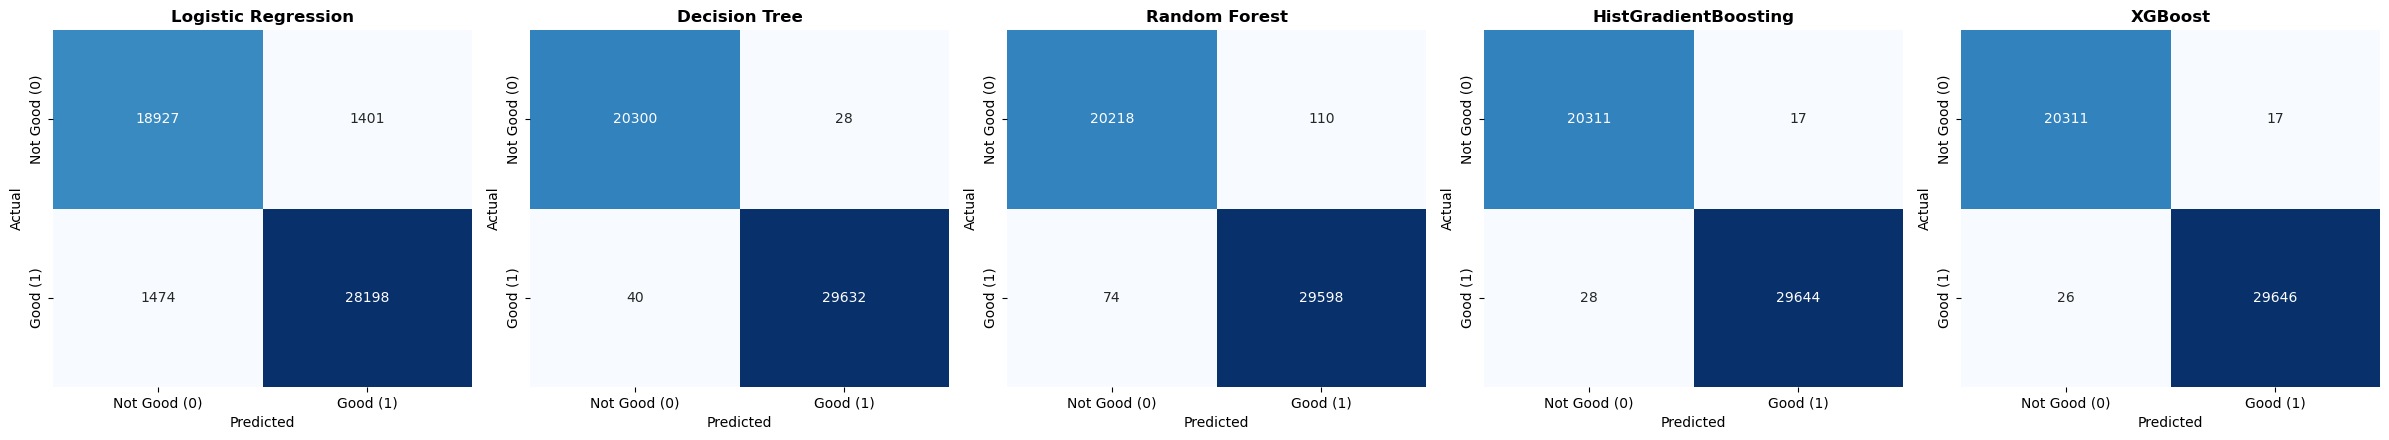

In [21]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(1, len(classifiers), figsize=(24, 4.5))

for ax, (name, model) in zip(axes, classifiers.items()):
    pipe = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ])
    pipe.fit(X_train_c, y_train_c)
    test_preds = pipe.predict(X_test_c)
    
    cm = confusion_matrix(y_test_c, test_preds)
    
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        xticklabels=["Not Good (0)", "Good (1)"],
        yticklabels=["Not Good (0)", "Good (1)"],
        ax=ax
    )
    ax.set_title(name, fontsize=12, fontweight="bold")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()


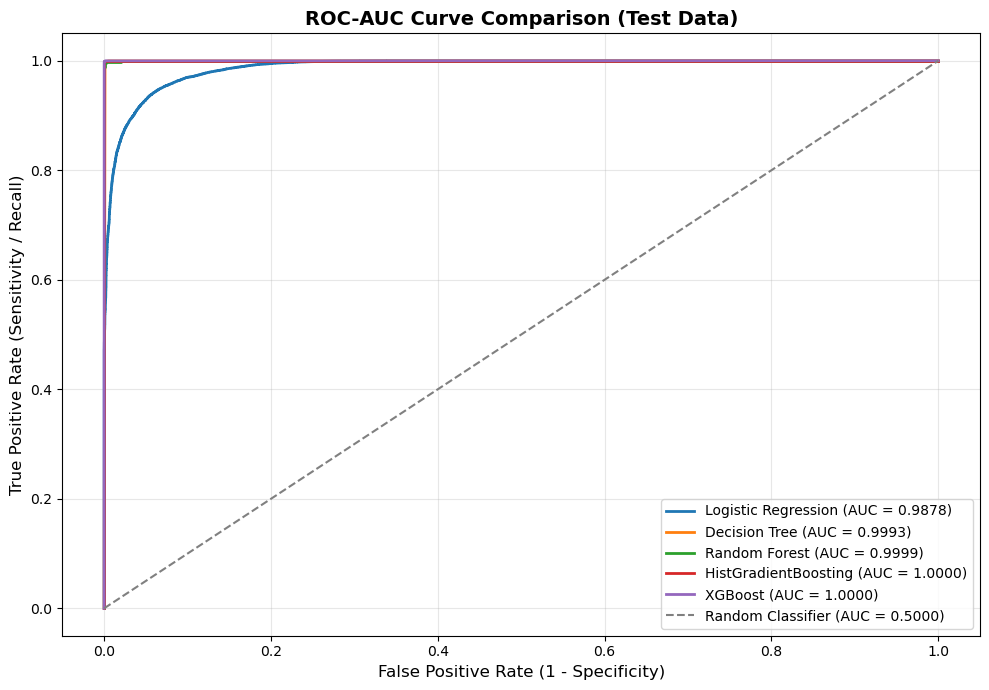

               Model  ROC-AUC Score
HistGradientBoosting         1.0000
             XGBoost         1.0000
       Random Forest         0.9999
       Decision Tree         0.9993
 Logistic Regression         0.9878


In [23]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

plt.figure(figsize=(10, 7))
auc_results = []

for name, model in classifiers.items():
    pipe = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ])
    pipe.fit(X_train_c, y_train_c)
    
    # Get predicted probabilities for the positive class (1)
    y_probs = pipe.predict_proba(X_test_c)[:, 1]
    
    # Compute False Positive Rate, True Positive Rate, and AUC
    fpr, tpr, _ = roc_curve(y_test_c, y_probs)
    auc_score = roc_auc_score(y_test_c, y_probs)
    
    auc_results.append({"Model": name, "ROC-AUC Score": round(auc_score, 4)})
    plt.plot(fpr, tpr, linewidth=2, label=f"{name} (AUC = {auc_score:.4f})")

# Plot random guessing diagonal reference line
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random Classifier (AUC = 0.5000)")

plt.title("ROC-AUC Curve Comparison (Test Data)", fontsize=14, fontweight="bold")
plt.xlabel("False Positive Rate (1 - Specificity)", fontsize=12)
plt.ylabel("True Positive Rate (Sensitivity / Recall)", fontsize=12)
plt.legend(loc="lower right", fontsize=10)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Print ranked AUC table
auc_df = pd.DataFrame(auc_results).sort_values(by="ROC-AUC Score", ascending=False)
print(auc_df.to_string(index=False))


In [22]:
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from xgboost import XGBRegressor
from sklearn.metrics import r2_score, mean_absolute_error, root_mean_squared_error

X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X, y_reg, test_size=0.2, random_state=42
)

regressors = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Decision Tree": DecisionTreeRegressor(max_depth=12, random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, max_depth=12, random_state=42, n_jobs=-1),
    "XGBoost": XGBRegressor(n_estimators=100, max_depth=6, learning_rate=0.1, random_state=42, n_jobs=-1)
}

reg_results = []

for name, model in regressors.items():
    pipe = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ])
    pipe.fit(X_train_r, y_train_r)
    preds = pipe.predict(X_test_r)
    
    reg_results.append({
        "Model": name,
        "R2 Score": round(r2_score(y_test_r, preds), 4),
        "MAE (Lakhs)": round(mean_absolute_error(y_test_r, preds), 2),
        "RMSE (Lakhs)": round(root_mean_squared_error(y_test_r, preds), 2)
    })

reg_summary = pd.DataFrame(reg_results).sort_values(by="R2 Score", ascending=False)
print("\n=== Regression Comparison ===")
print(reg_summary.to_string(index=False))



=== Regression Comparison ===
            Model  R2 Score  MAE (Lakhs)  RMSE (Lakhs)
          XGBoost    1.0000         0.85          1.09
    Random Forest    0.9990         4.09          6.47
    Decision Tree    0.9987         4.62          7.30
Linear Regression    0.9983         5.53          8.30
 Ridge Regression    0.9983         5.53          8.30


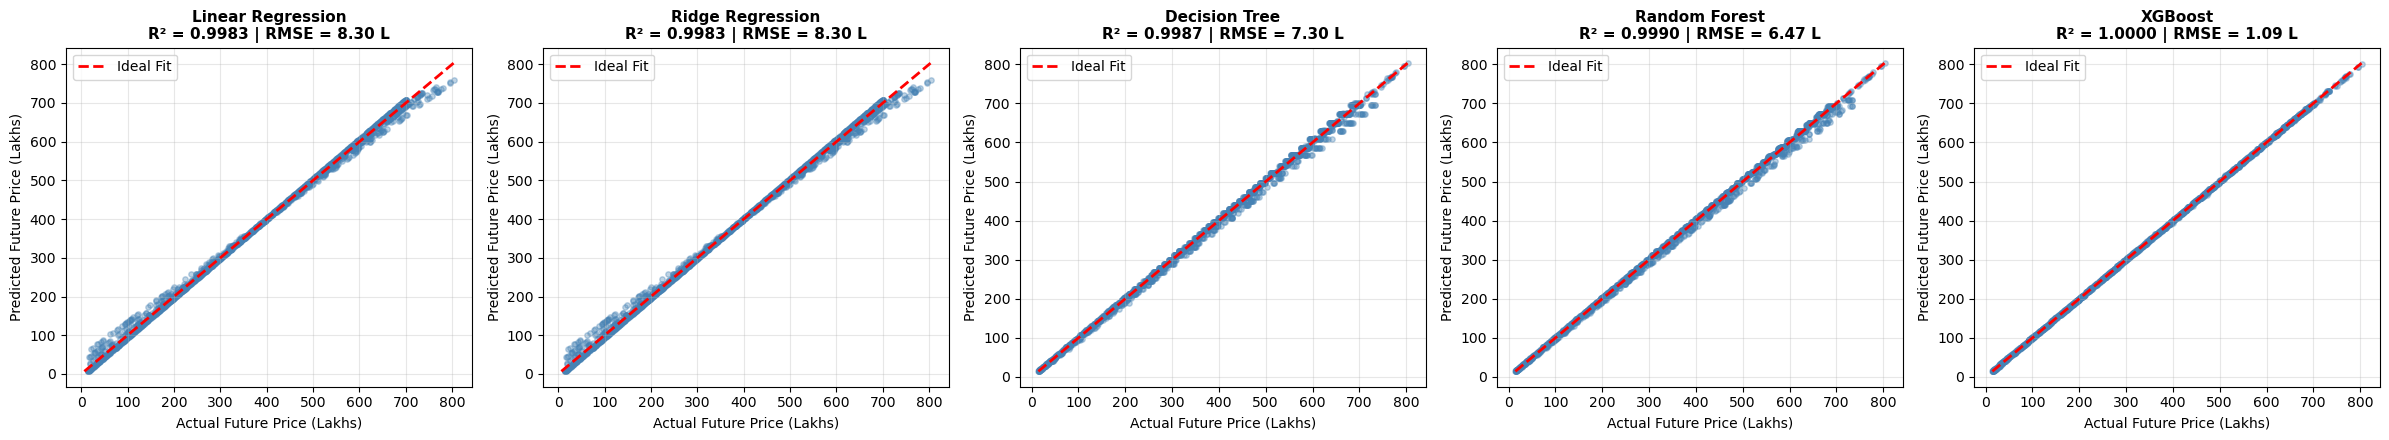

In [26]:

# Sample 2,000 test points for fast, clean plotting
sample_idx = np.random.RandomState(42).choice(len(y_test_r), size=2000, replace=False)
y_test_sample = y_test_r.iloc[sample_idx]

fig, axes = plt.subplots(1, len(regressors), figsize=(24, 4.5))

for ax, (name, model) in zip(axes, regressors.items()):
    pipe = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ])
    pipe.fit(X_train_r, y_train_r)
    test_preds = pipe.predict(X_test_r)
    
    # Calculate full test set metrics
    r2 = r2_score(y_test_r, test_preds)
    rmse = root_mean_squared_error(y_test_r, test_preds)
    
    # Plot sampled Actual vs Predicted points
    preds_sample = test_preds[sample_idx]
    ax.scatter(y_test_sample, preds_sample, alpha=0.35, s=15, color="steelblue")
    
    # Plot ideal diagonal line (y = x)
    min_val = min(y_test_sample.min(), preds_sample.min())
    max_val = max(y_test_sample.max(), preds_sample.max())
    ax.plot([min_val, max_val], [min_val, max_val], color="red", linestyle="--", linewidth=2, label="Ideal Fit")
    
    ax.set_title(f"{name}\nR² = {r2:.4f} | RMSE = {rmse:.2f} L", fontsize=11, fontweight="bold")
    ax.set_xlabel("Actual Future Price (Lakhs)")
    ax.set_ylabel("Predicted Future Price (Lakhs)")
    ax.legend(loc="upper left")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [27]:
#%pip install mlflow

   ---------------------------------------- 0.0/12.6 MB ? eta -:--:--
   - -------------------------------------- 0.5/12.6 MB 3.7 MB/s eta 0:00:04
   -------- ------------------------------- 2.6/12.6 MB 8.2 MB/s eta 0:00:02
   ---------- ----------------------------- 3.4/12.6 MB 7.0 MB/s eta 0:00:02
   -------------- ------------------------- 4.5/12.6 MB 5.9 MB/s eta 0:00:02
   ----------------- ---------------------- 5.5/12.6 MB 5.7 MB/s eta 0:00:02
   ----------------- ---------------------- 5.5/12.6 MB 5.7 MB/s eta 0:00:02
   ------------------- -------------------- 6.0/12.6 MB 4.6 MB/s eta 0:00:02
   ------------------- -------------------- 6.0/12.6 MB 4.6 MB/s eta 0:00:02
   ------------------- -------------------- 6.3/12.6 MB 3.5 MB/s eta 0:00:02
   --------------------- ------------------ 6.8/12.6 MB 3.3 MB/s eta 0:00:02
   ----------------------- ---------------- 7.3/12.6 MB 3.4 MB/s eta 0:00:02
   ------------------------ --------------- 7.9/12.6 MB 3.1 MB/s eta 0:00:02
   ---

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
jupyterlab 4.4.7 requires ipykernel!=6.30.0,>=6.5.0, but you have ipykernel 6.30.0 which is incompatible.
spyder 6.1.0 requires ipython!=8.17.1,!=9.1.0,!=9.2.0,!=9.3.0,!=9.4.0,<10.0.0,>=8.15.0, but you have ipython 9.4.0 which is incompatible.
streamlit 1.51.0 requires protobuf<7,>=3.20, but you have protobuf 7.36.2 which is incompatible.


In [29]:
import mlflow
import mlflow.sklearn
import mlflow.xgboost
from mlflow.models import infer_signature
from mlflow.tracking import MlflowClient

# Use SQLite backend so Model Registry works locally
mlflow.set_tracking_uri("sqlite:///mlflow.db")
mlflow.set_experiment("Real_Estate_Investment_Advisor")

print("Tracking URI:", mlflow.get_tracking_uri())


Tracking URI: sqlite:///mlflow.db


In [33]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

best_clf_f1 = -1
best_clf_run_id = None
best_clf_name = ""

for name, model in classifiers.items():
    with mlflow.start_run(run_name=f"CLF_{name}") as run:
        pipe = Pipeline(steps=[
            ("preprocessor", preprocessor),  
            ("model", model)
        ])
        pipe.fit(X_train_c, y_train_c)
        
        preds = pipe.predict(X_test_c)
        probs = pipe.predict_proba(X_test_c)[:, 1]
        
        # Calculate metrics
        acc = accuracy_score(y_test_c, preds)
        prec = precision_score(y_test_c, preds)
        rec = recall_score(y_test_c, preds)
        f1 = f1_score(y_test_c, preds)
        auc = roc_auc_score(y_test_c, probs)
        
        # Log tags, parameters, and metrics
        mlflow.set_tag("task", "classification")
        mlflow.log_param("model_type", name)
        mlflow.log_metrics({
            "test_accuracy": acc,
            "test_precision": prec,
            "test_recall": rec,
            "test_f1": f1,
            "test_roc_auc": auc
        })
        
        # Infer input/output schema and log the full pipeline
        signature = infer_signature(X_test_c.head(5), preds[:5])
        mlflow.sklearn.log_model(
        sk_model=pipe,
        name="model",
        signature=signature,
        serialization_format="cloudpickle"
)
        
        print(f"Logged {name} | F1: {f1:.4f} | AUC: {auc:.4f}")
        
        # Track the best classifier
        if f1 > best_clf_f1:
            best_clf_f1 = f1
            best_clf_run_id = run.info.run_id
            best_clf_name = name

print(f"\nBest Classifier: {best_clf_name} (Run ID: {best_clf_run_id})")


C:\Users\ADMIN\anaconda3\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
2026/11/13 19:49:05 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during

Logged Logistic Regression | F1: 0.9515 | AUC: 0.9878


C:\Users\ADMIN\anaconda3\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
2026/11/13 19:49:19 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during

Logged Decision Tree | F1: 0.9989 | AUC: 0.9993


C:\Users\ADMIN\anaconda3\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
2026/11/13 19:49:54 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during

Logged Random Forest | F1: 0.9969 | AUC: 0.9999


C:\Users\ADMIN\anaconda3\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
2026/11/13 19:50:28 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during

Logged HistGradientBoosting | F1: 0.9992 | AUC: 1.0000


C:\Users\ADMIN\anaconda3\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
2026/11/13 19:50:47 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during

Logged XGBoost | F1: 0.9993 | AUC: 1.0000

Best Classifier: XGBoost (Run ID: b039c6dd04d44399b24e044ab5ba8ce8)


In [36]:
from sklearn.metrics import r2_score, mean_absolute_error, root_mean_squared_error

best_reg_r2 = -float("inf")
best_reg_run_id = None
best_reg_name = ""

for name, model in regressors.items():
    with mlflow.start_run(run_name=f"REG_{name}") as run:
        pipe = Pipeline(steps=[
            ("preprocessor", preprocessor), 
            ("model", model)
        ])
        pipe.fit(X_train_r, y_train_r)
        
        preds = pipe.predict(X_test_r)
        
        # Calculate metrics
        r2 = r2_score(y_test_r, preds)
        rmse = root_mean_squared_error(y_test_r, preds)
        mae = mean_absolute_error(y_test_r, preds)
        
        # Log tags, parameters, and metrics
        mlflow.set_tag("task", "regression")
        mlflow.log_param("model_type", name)
        mlflow.log_metrics({
            "test_r2": r2,
            "test_rmse": rmse,
            "test_mae": mae
        })
        
        # Infer schema and log full pipeline
        signature = infer_signature(X_test_c.head(5), preds[:5])
        mlflow.sklearn.log_model(
        sk_model=pipe,
        name="model",
        signature=signature,
        serialization_format="cloudpickle"
        )
        print(f"Logged {name} | R2: {r2:.4f} | RMSE: {rmse:.2f}")
        
        # Track the best regressor
        if r2 > best_reg_r2:
            best_reg_r2 = r2
            best_reg_run_id = run.info.run_id
            best_reg_name = name

print(f"\nBest Regressor: {best_reg_name} (Run ID: {best_reg_run_id})")


C:\Users\ADMIN\anaconda3\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
2026/11/13 19:52:46 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during

Logged Linear Regression | R2: 0.9983 | RMSE: 8.30


C:\Users\ADMIN\anaconda3\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
2026/11/13 19:52:58 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during

Logged Ridge Regression | R2: 0.9983 | RMSE: 8.30


C:\Users\ADMIN\anaconda3\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
2026/11/13 19:53:15 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during

Logged Decision Tree | R2: 0.9987 | RMSE: 7.30


C:\Users\ADMIN\anaconda3\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
2026/11/13 19:56:04 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during

Logged Random Forest | R2: 0.9990 | RMSE: 6.47


C:\Users\ADMIN\anaconda3\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
2026/11/13 19:56:23 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during

Logged XGBoost | R2: 1.0000 | RMSE: 1.09

Best Regressor: XGBoost (Run ID: 4358406281e647beae70d729e2b324f9)


In [37]:
client = MlflowClient()

# 1. Register Best Classifier
clf_model_name = "RealEstate_GoodInvestment_Classifier"
clf_uri = f"runs:/{best_clf_run_id}/model"
clf_reg = mlflow.register_model(model_uri=clf_uri, name=clf_model_name)
client.set_registered_model_alias(clf_model_name, "champion", clf_reg.version)

# 2. Register Best Regressor
reg_model_name = "RealEstate_FuturePrice5Y_Regressor"
reg_uri = f"runs:/{best_reg_run_id}/model"
reg_reg = mlflow.register_model(model_uri=reg_uri, name=reg_model_name)
client.set_registered_model_alias(reg_model_name, "champion", reg_reg.version)

print(f"Registered {clf_model_name} v{clf_reg.version} as @champion")
print(f"Registered {reg_model_name} v{reg_reg.version} as @champion")


Successfully registered model 'RealEstate_GoodInvestment_Classifier'.
2026/11/13 19:56:51 WARNING mlflow.tracking._model_registry.fluent: Run with id b039c6dd04d44399b24e044ab5ba8ce8 has no artifacts at artifact path 'model', registering model based on models:/m-ac2e1a26b8704169adb59116a3b4ae71 instead
Created version '1' of model 'RealEstate_GoodInvestment_Classifier'.
Successfully registered model 'RealEstate_FuturePrice5Y_Regressor'.
2026/11/13 19:56:51 WARNING mlflow.tracking._model_registry.fluent: Run with id 4358406281e647beae70d729e2b324f9 has no artifacts at artifact path 'model', registering model based on models:/m-e6f63e5954af4f4fad0c2a19f9cebfac instead
Created version '1' of model 'RealEstate_FuturePrice5Y_Regressor'.


Registered RealEstate_GoodInvestment_Classifier v1 as @champion
Registered RealEstate_FuturePrice5Y_Regressor v1 as @champion


In [38]:
# Load registered pipelines using their @champion alias
loaded_clf = mlflow.sklearn.load_model(f"models:/{clf_model_name}@champion")
loaded_reg = mlflow.sklearn.load_model(f"models:/{reg_model_name}@champion")

# Verify predictions on 5 raw test rows
sample_clf_preds = loaded_clf.predict(X_test_c.head(5))
sample_reg_preds = loaded_reg.predict(X_test_r.head(5))

print("Verified Good_Investment Predictions:", sample_clf_preds)
print("Verified Future_Price_5Y Predictions (Lakhs):", sample_reg_preds.round(2))


Verified Good_Investment Predictions: [0 0 1 1 1]
Verified Future_Price_5Y Predictions (Lakhs): [360.2  120.12 347.22 477.02 174.45]


In [41]:
!mlflow ui --backend-store-uri sqlite:///mlflow.db 


^C


In [42]:
import importlib.util
print("Installed:", importlib.util.find_spec("streamlit") is not None)


Installed: True


In [5]:
!streamlit run app.py

# http://localhost:8501/


^C


In [4]:
import os
import joblib
import mlflow
import mlflow.sklearn
from mlflow.tracking import MlflowClient

mlflow.set_tracking_uri("sqlite:///mlflow.db")
client = MlflowClient()

clf_ver = client.get_model_version_by_alias("RealEstate_GoodInvestment_Classifier", "champion")
reg_ver = client.get_model_version_by_alias("RealEstate_FuturePrice5Y_Regressor", "champion")

print("CLF source:", clf_ver.source)
print("REG source:", reg_ver.source)

# List all MLmodel directories currently inside mlruns
found_models = []
for root, dirs, files in os.walk("mlruns"):
    if "MLmodel" in files:
        found_models.append(root)
        print("Found MLmodel at:", root)

# Match by source folder name (e.g., m-xxxx)
clf_folder_id = os.path.basename(clf_ver.source.rstrip("/\\"))
reg_folder_id = os.path.basename(reg_ver.source.rstrip("/\\"))

clf_path = next((p for p in found_models if clf_folder_id in p), None)
reg_path = next((p for p in found_models if reg_folder_id in p), None)

if clf_path and reg_path:
    clf = mlflow.sklearn.load_model(clf_path)
    reg = mlflow.sklearn.load_model(reg_path)
    joblib.dump(clf, "champion_classifier.joblib")
    joblib.dump(reg, "champion_regressor.joblib")
    print("\nSUCCESS! Exported champion_classifier.joblib and champion_regressor.joblib!")
else:
    print("\nCould not auto-match. Copy the exact printed paths above to load manually.")


CLF source: models:/m-ac2e1a26b8704169adb59116a3b4ae71
REG source: models:/m-e6f63e5954af4f4fad0c2a19f9cebfac
Found MLmodel at: mlruns\1\models\m-240f5be1445d4572a2202c2fdf7177d6\artifacts
Found MLmodel at: mlruns\1\models\m-5ee0f756647b4ee2b85ce3829f379c6c\artifacts
Found MLmodel at: mlruns\1\models\m-672aa7ac87f44b3296d0593175d0a97f\artifacts
Found MLmodel at: mlruns\1\models\m-6ce689663b964ff39b83b0843d235daa\artifacts
Found MLmodel at: mlruns\1\models\m-98cb68b613e64c69bab27c7f9ab6d951\artifacts
Found MLmodel at: mlruns\1\models\m-ac2e1a26b8704169adb59116a3b4ae71\artifacts
Found MLmodel at: mlruns\1\models\m-ac5b74c7f8a04e8596a4745462078ed1\artifacts
Found MLmodel at: mlruns\1\models\m-d84660f08dba49648ee9bcb556802669\artifacts
Found MLmodel at: mlruns\1\models\m-e1828602b57e434f81f018737bba9a49\artifacts
Found MLmodel at: mlruns\1\models\m-e6f63e5954af4f4fad0c2a19f9cebfac\artifacts
Found MLmodel at: mlruns\1\models\m-f170355d43104d42b82b637c6eadbbb8\artifacts
Found MLmodel at: mlr